In [78]:
import numpy as np
import scipy
import pandas as pd

import matplotlib as mpl
import matplotlib.pyplot as plt

import odrpack as odr

from uncertainties import ufloat
from uncertainties import umath
from uncertainties import unumpy as un

In [79]:
#para meter

inFileName = "datydata.xlsx"

df = {
    "Cu": pd.read_excel(inFileName, sheet_name="coble", decimal = ","),
    "Al": pd.read_excel(inFileName, sheet_name="alimunio", decimal = ","),
    "Air": pd.read_excel(inFileName, sheet_name="aire", decimal = ","),
}

tiempot = {
    "Cu": un.uarray(df["Cu"].to_numpy()[:,0], 5),
    "Al": un.uarray(df["Al"].to_numpy()[:,0], 5),
    "Air": un.uarray(df["Air"].to_numpy()[:,0], 5),
}

temperaturaT = {
    "Cu": un.uarray(df["Cu"].to_numpy()[:,1], 0.01/np.sqrt(12)),
    "Al": un.uarray(df["Al"].to_numpy()[:,1], 0.01/np.sqrt(12)),
    "Air": un.uarray(df["Air"].to_numpy()[:,1], 0.01/np.sqrt(12)),
}

waterMass = {
    "Cu": ufloat(566.7, 0.1/np.sqrt(12)) - ufloat(251.9, 0.1/np.sqrt(12)),
    "Al": ufloat(605.3, 0.1/np.sqrt(12)) - ufloat(251.9, 0.1/np.sqrt(12)),
    "Air": ufloat(580.0, 0.1/np.sqrt(12)) - ufloat(251.9, 0.1/np.sqrt(12)),
}

waterHeatCapacity = 4.184

calorimeterCapacity = ufloat(184,6)

crossSectionS = 4.91e-4

distanciaTerminales = {
    "Cu": ufloat(25.45e-2, 0.005e-2/np.sqrt(12)),
    "Al": ufloat(25.4e-2, 0.005e-2/np.sqrt(12)),
}

gradDf = {
    "Cu": pd.read_excel(inFileName, sheet_name="gradcoble", decimal = ","),
    "Al": pd.read_excel(inFileName, sheet_name="gradalimunio", decimal = ","),
}

'''deltaT = {
    "Cu": un.uarray(gradDf["Cu"]["T_A (ºC)"], 0.01 / np.sqrt(12)) - un.uarray(gradDf["Cu"]["T_B (ºC)"], 0.01 / np.sqrt(12)),
    "Al": un.uarray(gradDf["Al"]["T_A (ºC)"], 0.01 / np.sqrt(12)) - un.uarray(gradDf["Al"]["T_B (ºC)"], 0.01 / np.sqrt(12))
}'''

deltaT = {
    "Cu": un.uarray(gradDf["Cu"]["DeltaTChic"],np.sqrt(2) * 0.01 / np.sqrt(12)),
    "Al": un.uarray(gradDf["Al"]["DeltaTChic"],np.sqrt(2) * 0.01 / np.sqrt(12)),
}

averageTForGrad = {
    "Cu": deltaT["Cu"].mean(),
    "Al": deltaT["Al"].mean(),
}

del df
del gradDf

In [80]:
p = {}
beta = {}
sdBeta = {}

portionDict = {
    "Cu": slice(6,None), #5
    "Al": slice(4,None), #4
    "Air": slice(3,15),
}

for experimento in ["Al", "Cu", "Air"]:

    portion = portionDict[experimento]

    X = tiempot[experimento][portion]
    Y = temperaturaT[experimento][portion]

    #=============================== Blocón de ODR_FIT ===============================

    def func(x, beta):
        return beta[0] * x + beta[1]

    beta0 = [0.03,0]

    fittingX = un.nominal_values(X)
    fittingY = un.nominal_values(Y)
    fittingXUncertainty = un.std_devs(X)
    fittingYUncertainty = un.std_devs(Y)

    sol = odr.odr_fit(func, fittingX, fittingY, beta0, weight_x = 1/(fittingXUncertainty**2), weight_y = 1/(fittingYUncertainty**2))

    pendiente = ufloat(sol.beta[0],sol.sd_beta[0])#np.sqrt(sol.cov_beta[0,0]))
    ordenada = ufloat(sol.beta[1],sol.sd_beta[1])#np.sqrt(sol.cov_beta[1,1]))

    print("pendiente = {:.3e}".format(pendiente))
    print("ordenada = {:.6e}".format(ordenada))

    print(f"χ² reducido = {sol.sum_square/(len(un.nominal_values(X))-len(sol.beta))}")
    #print(f"pearson = {scipy.stats.pearsonr(fittingX, fittingY).statistic}")
    print(f"R² = {scipy.stats.pearsonr(fittingX, fittingY).statistic**2}")

    #=================================================================================

    beta[experimento] = sol.beta
    sdBeta[experimento] = sol.sd_beta
    p[experimento] = pendiente

pendiente = (5.485+/-0.097)e-03
ordenada = (2.745997+/-0.000211)e+02
χ² reducido = 0.30859581420680116
R² = 0.998452304556266
pendiente = (6.839+/-0.114)e-03
ordenada = (2.754686+/-0.000278)e+02
χ² reducido = 0.09915073728499806
R² = 0.9991678554446027
pendiente = (3.667+/-0.015)e-03
ordenada = (2.733342+/-0.000080)e+02
χ² reducido = 0.3169354336482312
R² = 0.9998422720544651


C:\Users\Alex\Plotting\.venv\Lib\site-packages\uncertainties\unumpy\core.py:84: FutureWarning: the uncertainties.unumpy.unumpy_to_numpy_matrix function is deprecated. It will be removed in a future release.
  warn(msg, FutureWarning)


In [81]:
dQdt = {
    "Cu": p["Cu"] * (waterMass["Cu"] * waterHeatCapacity + calorimeterCapacity),
    "Al": p["Al"] * (waterMass["Al"] * waterHeatCapacity + calorimeterCapacity),
    "Air": p["Air"] * (waterMass["Air"] * waterHeatCapacity + calorimeterCapacity),
}

dTdx = {
    "Cu": averageTForGrad["Cu"] / distanciaTerminales["Cu"],
    "Al": averageTForGrad["Al"] / distanciaTerminales["Al"],
}

kappa = {
    "Cu": - (dQdt["Air"] - dQdt["Cu"]) / (crossSectionS * dTdx["Cu"]),
    "Al": - (dQdt["Air"] - dQdt["Al"]) / (crossSectionS * dTdx["Al"]),
}
kappaTheoretical = {
    "Cu": 401,
    "Al": 237,
}

relativeError = {}
for experimento in {"Cu", "Al"}:
    relativeError[experimento] = 100 * (kappaTheoretical[experimento] - un.nominal_values(kappa[experimento])) / kappaTheoretical[experimento]

print("kappacobre = {:.1f} J/(m·K)".format(kappa["Cu"]) + "; relative error = {:.1f}%".format(relativeError["Cu"]))
print("kappaalimunio = {:.1f} J/(m·K)".format(kappa["Al"]) + "; relative error = {:.1f}%".format(relativeError["Al"]))

lorenzNumber = {
    "Al": kappa["Al"] / (ufloat(3.585,0.046) * 10**7 * 293.15),
    "Cu": kappa["Cu"] / (ufloat(5.427,0.084) * 10**7 * 293.15),
}

kappacobre = 88.6+/-3.4 J/(m·K); relative error = 77.9%
kappaalimunio = 110.6+/-5.3 J/(m·K); relative error = 53.3%


C:\Users\Alex\Plotting\.venv\Lib\site-packages\uncertainties\core.py:526: FutureWarning: AffineScalarFunc.error_components() is currently an instance method. This method is deprecated. In a future release it will be replaced with an instance property by the same name. It will be accessed by AffineScalarFunc.error_components (with no parentheses).
  return float(sqrt(sum(delta**2 for delta in self.error_components().values())))
C:\Users\Alex\Plotting\.venv\Lib\site-packages\uncertainties\core.py:491: FutureWarning: AffineScalarFunc.derivatives() is deprecated. It will be removed in a future release.
  for variable, derivative in self.derivatives.items():


# Fin de cuentas

In [82]:
pallete = ["#5f0f40","#9a031e","#fb8b24","#e36414","#0f4c5c"]

In [83]:
for experimento in {"Cu", "Al", "Air"}:
    temperaturaT[experimento] = temperaturaT[experimento] - 273.15
    beta[experimento][1] = beta[experimento][1] - 273.15

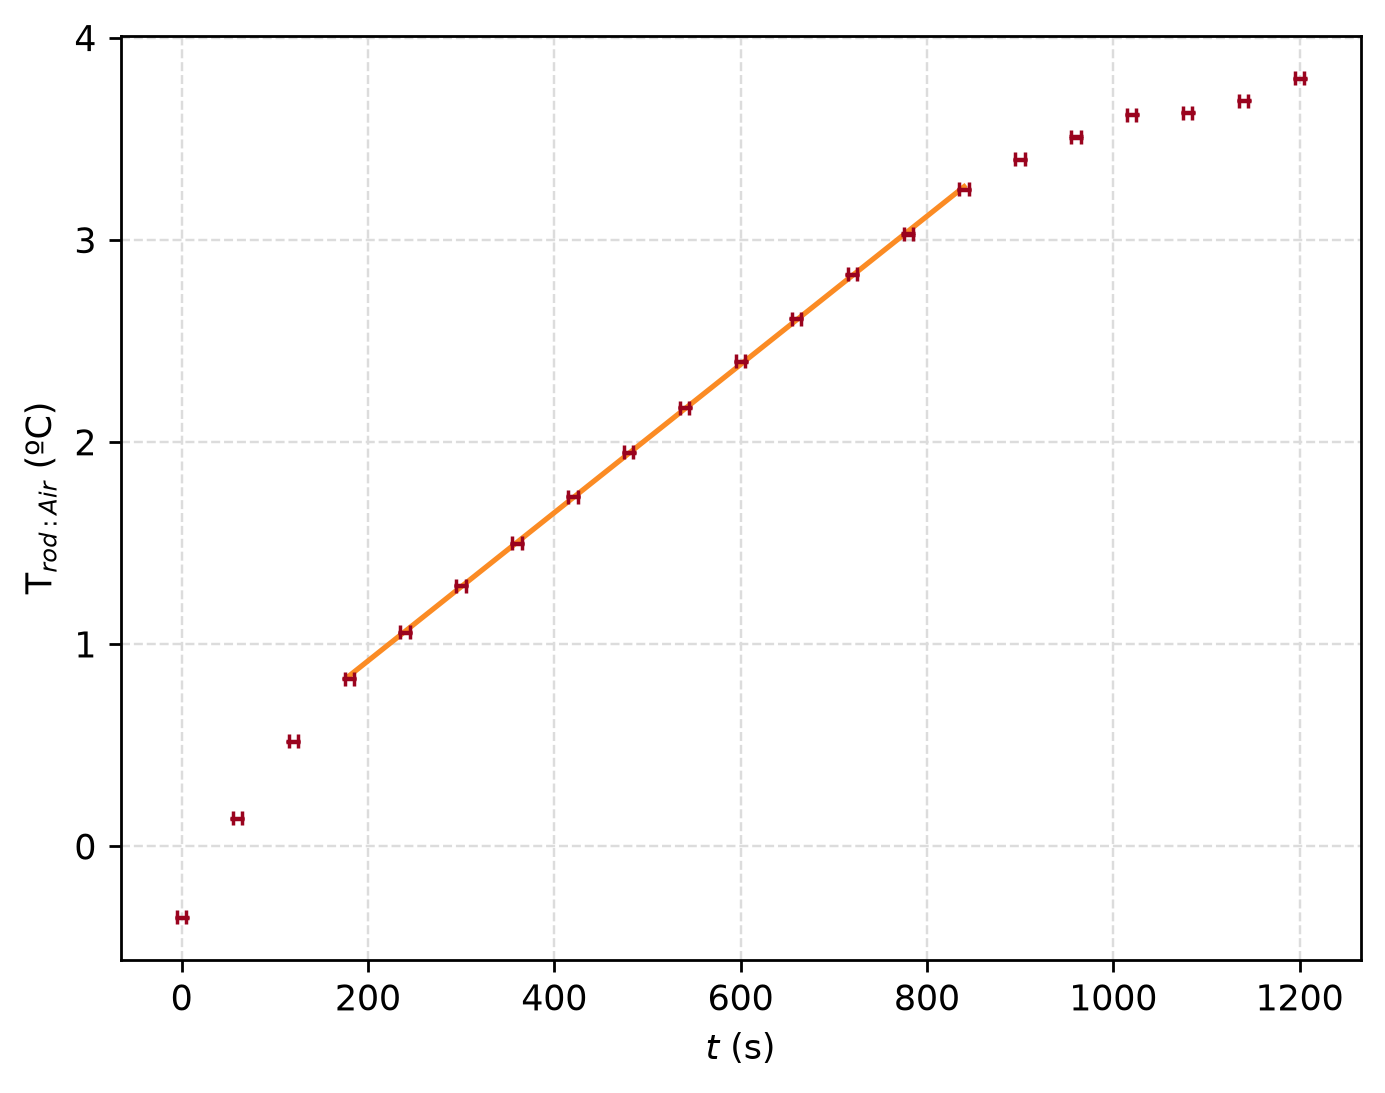

In [84]:
experimento = "Air"

portion = portionDict[experimento]

X = tiempot[experimento]
Y = temperaturaT[experimento]

fig, ax = plt.subplots(dpi = 250)

ax.errorbar(x = un.nominal_values(X), y = un.nominal_values(Y), xerr = un.std_devs(X), yerr = un.std_devs(Y),label=experimento, ls = "", marker = "", markersize = 2, capsize=2, zorder = 10, elinewidth=.5, ecolor = pallete[1])

ax.plot(un.nominal_values(X[portion]), func(un.nominal_values(X[portion]), beta[experimento]), color = pallete[2])

ax.set(xlabel = r"$t$ (s)", ylabel = f"T$_{{rod:{experimento}}}$ (ºC)")

ax.grid(zorder=0,color='gainsboro', linestyle='--', linewidth=0.7)

plt.savefig(f"Tvst{experimento}.png", dpi = 250, bbox_inches='tight')

plt.show()

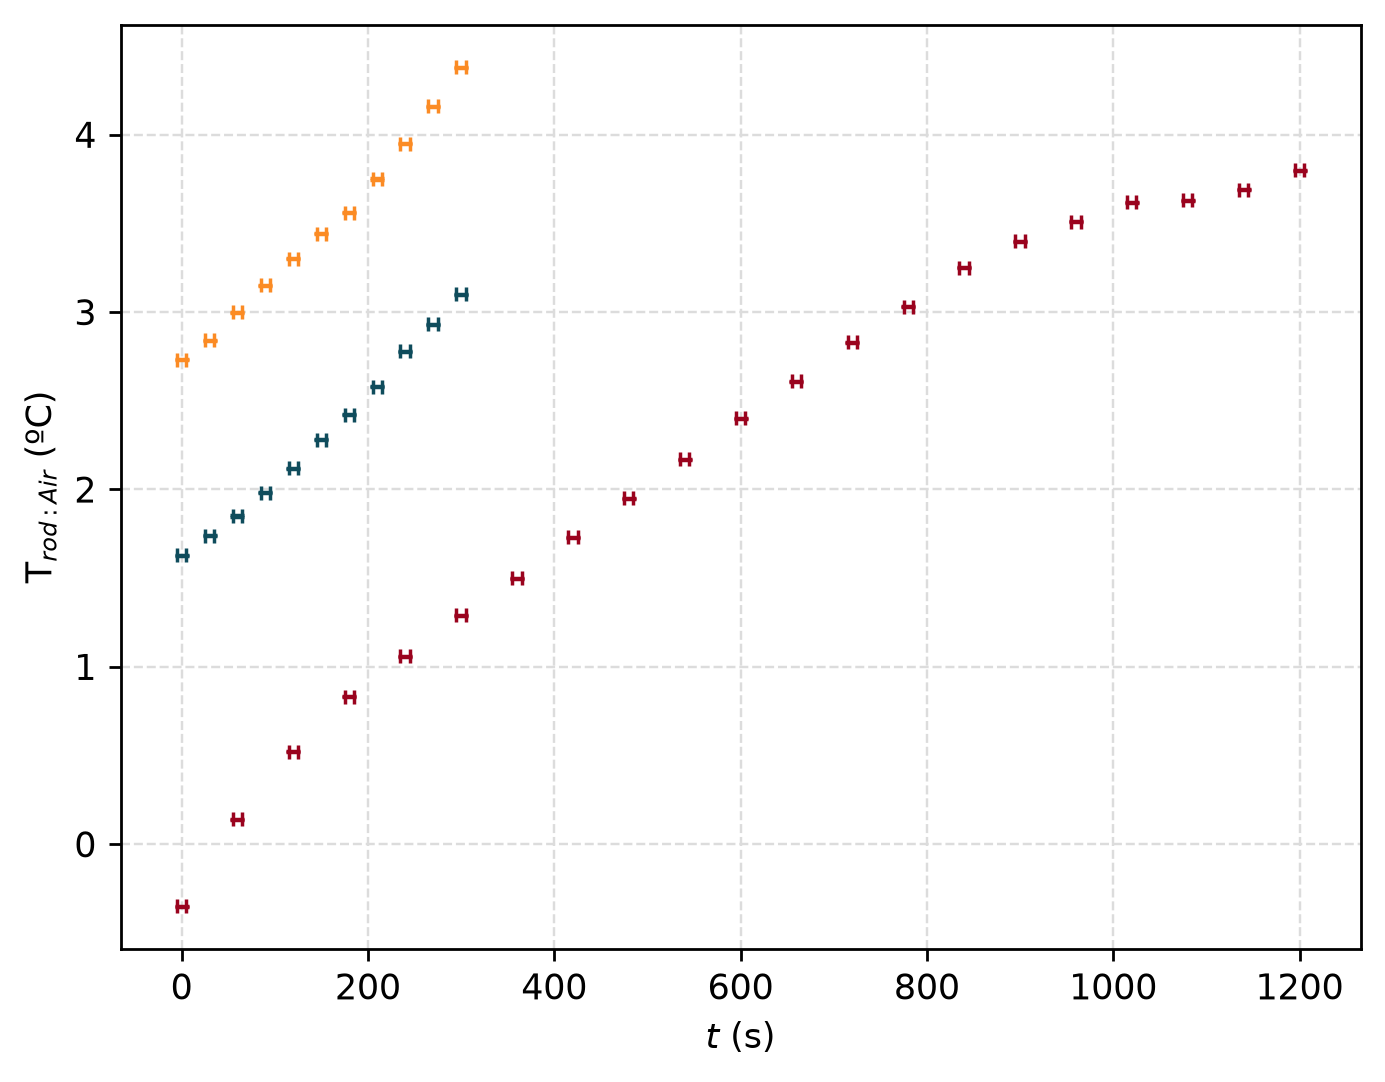

In [85]:
fig, ax = plt.subplots(dpi = 250)

X = tiempot["Cu"]
Y = temperaturaT["Cu"]

ax.errorbar(x = un.nominal_values(X), y = un.nominal_values(Y), xerr = un.std_devs(X), yerr = un.std_devs(Y),label="Cu", ls = "", marker = "", markersize = 2, capsize=2, zorder = 10, elinewidth=.5, ecolor = pallete[2])

X = tiempot["Al"]
Y = temperaturaT["Al"]

ax.errorbar(x = un.nominal_values(X), y = un.nominal_values(Y), xerr = un.std_devs(X), yerr = un.std_devs(Y),label="Al", ls = "", marker = "", markersize = 2, capsize=2, zorder = 10, elinewidth=.5, ecolor = pallete[4])

X = tiempot["Air"]
Y = temperaturaT["Air"]

ax.errorbar(x = un.nominal_values(X), y = un.nominal_values(Y), xerr = un.std_devs(X), yerr = un.std_devs(Y),label="Air", ls = "", marker = "", markersize = 2, capsize=2, zorder = 10, elinewidth=.5, ecolor = pallete[1])


ax.set(xlabel = r"$t$ (s)", ylabel = f"T$_{{rod:{experimento}}}$ (ºC)")

ax.grid(zorder=0,color='gainsboro', linestyle='--', linewidth=0.7)

plt.savefig(f"Tvstcomun.png", dpi = 250, bbox_inches='tight')

plt.show()

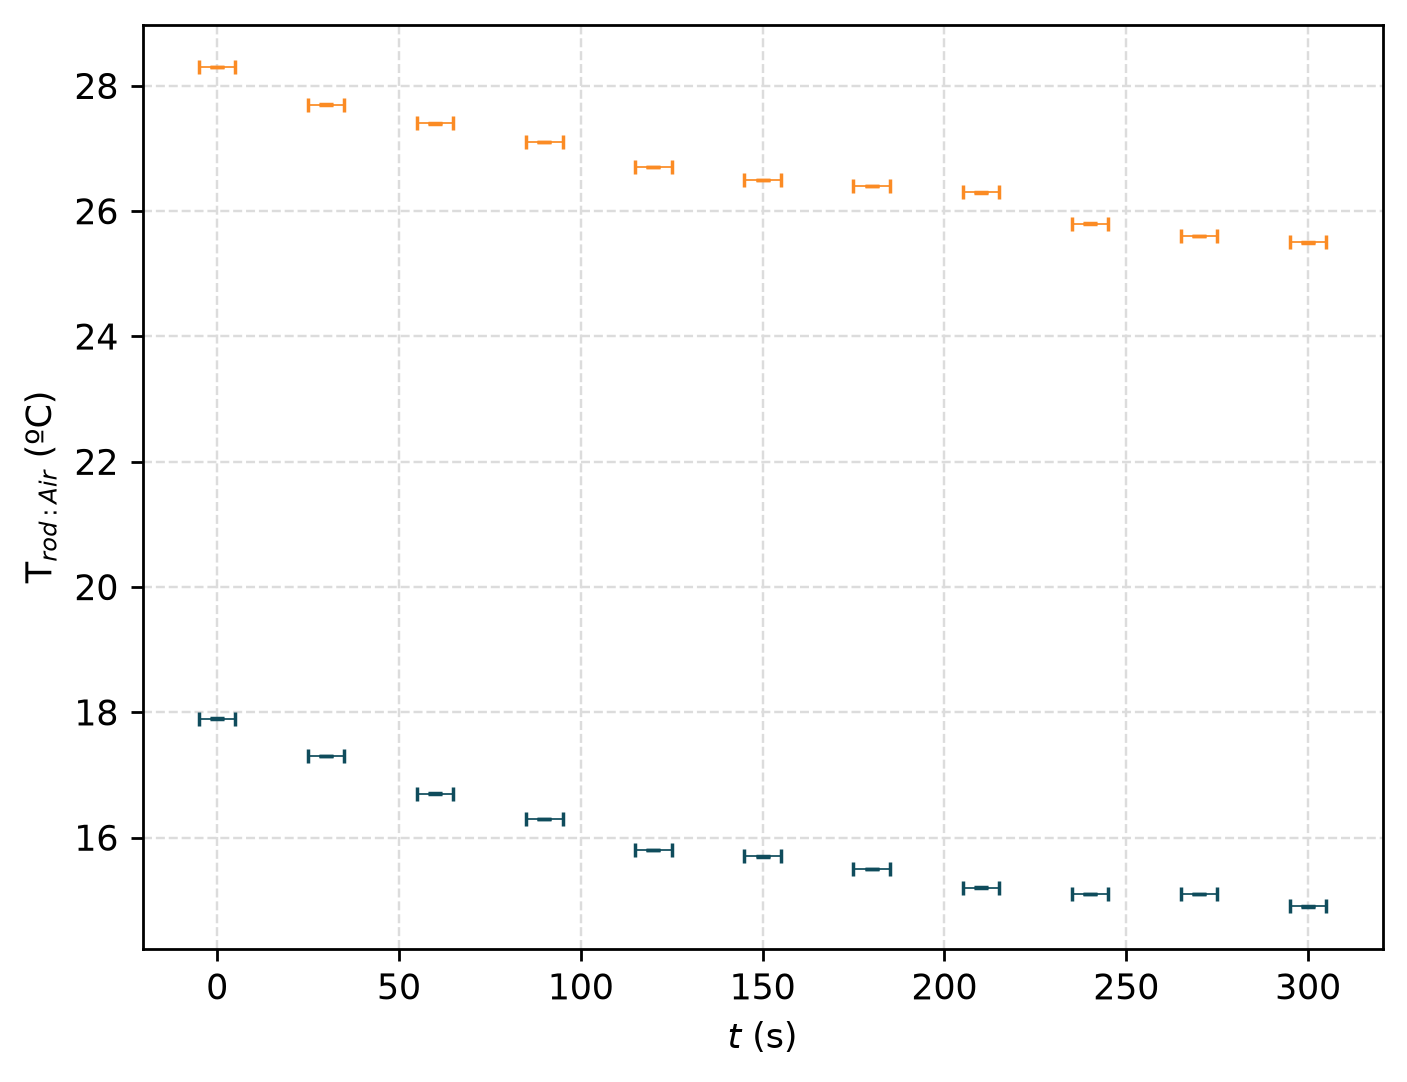

In [86]:
fig, ax = plt.subplots(dpi = 250)

X = tiempot["Cu"]
Y = deltaT["Cu"]

ax.errorbar(x = un.nominal_values(X), y = un.nominal_values(Y), xerr = un.std_devs(X), yerr = un.std_devs(Y),label="Cu", ls = "", marker = "", markersize = 2, capsize=2, zorder = 10, elinewidth=.5, ecolor = pallete[2])

X = tiempot["Al"]
Y = deltaT["Al"]

ax.errorbar(x = un.nominal_values(X), y = un.nominal_values(Y), xerr = un.std_devs(X), yerr = un.std_devs(Y),label="Al", ls = "", marker = "", markersize = 2, capsize=2, zorder = 10, elinewidth=.5, ecolor = pallete[4])


ax.set(xlabel = r"$t$ (s)", ylabel = f"T$_{{rod:{experimento}}}$ (ºC)")

ax.grid(zorder=0,color='gainsboro', linestyle='--', linewidth=0.7)

plt.savefig(f"deltaTvstcomun.png", dpi = 250, bbox_inches='tight')

plt.show()